# WeatherXAI-BD:  Extreme Event-Aware Explainable Weather Forecasting  Using Hybrid LSTM–Transformer Modeling

This notebook implements the complete WeatherXAI-BD framework for explainable weather forecasting in Bangladesh.

The workflow includes:

1. Dataset preparation
2. Meteorological feature engineering
3. Sequential data generation
4. Multi-task deep learning forecasting
5. Model comparison
6. Explainable AI analysis
7. Agricultural risk assessment

The implemented models include:

- LSTM
- Transformer
- Hybrid LSTM–Transformer

The framework predicts:

- Future meteorological variables
- Rainfall occurrence
- Extreme rainfall events

Temporal SHAP analysis is applied to interpret model decisions, while WARI is used for agricultural risk assessment.

In [71]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub


/kaggle/input/datasets/mdforhadmia/weather-2021-2024-dataset/WEATHER_2021_2024_MERGED.csv
/kaggle/input/datasets/mdforhadmia/daily-weather-data/daily_weather_data.csv


# Step 01: Dataset Loading and Exploratory Data Analysis

This step loads the NASA POWER-based daily meteorological dataset and performs
initial exploratory analysis. The objective is to understand dataset structure,
identify data quality issues, analyze statistical characteristics, and visualize
weather variable distributions before preprocessing.

The following analyses are performed:

1. Dataset loading and structure verification
2. Feature identification
3. Statistical summary analysis
4. Missing value detection
5. Duplicate record checking
6. Meteorological variable distribution analysis
7. Precipitation distribution analysis
8. Correlation analysis among weather variables

The outputs generated in this step are used to validate the dataset quality and
support further preprocessing and feature engineering.

Libraries imported successfully
Dataset loaded successfully
--------------------------------
Dataset Shape: (105192, 10)

Dataset Information
--------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105192 entries, 0 to 105191
Data columns (total 10 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   DAY            105192 non-null  int64  
 1   DAY.1          105192 non-null  int64  
 2   MONTH          105192 non-null  int64  
 3   YEAR           105192 non-null  int64  
 4   LAT            105192 non-null  float64
 5   LON            105192 non-null  float64
 6   HUMIDITY       105192 non-null  float64
 7   TEMPERATURE    105192 non-null  float64
 8   WIND_SPEED     105192 non-null  float64
 9   PRECIPITATION  105192 non-null  float64
dtypes: float64(6), int64(4)
memory usage: 8.0 MB

First Five Records
--------------------------------


,DAY,DAY.1,MONTH,YEAR,LAT,LON,HUMIDITY,TEMPERATURE,WIND_SPEED,PRECIPITATION
0,1,1,1,2021,20.5,88.12,10.47,23.80,4.41,0.0
1,1,1,1,2021,20.5,88.75,10.44,23.63,3.98,0.0
2,1,1,1,2021,20.5,89.38,10.70,23.31,3.73,0.0
3,1,1,1,2021,20.5,90.00,11.23,22.77,3.92,0.0
4,1,1,1,2021,20.5,90.62,11.80,22.47,4.16,0.0



Dataset Features
--------------------------------
1 . DAY
2 . DAY.1
3 . MONTH
4 . YEAR
5 . LAT
6 . LON
7 . HUMIDITY
8 . TEMPERATURE
9 . WIND_SPEED
10 . PRECIPITATION

Temporal Features:
['DAY', 'MONTH', 'YEAR']

Spatial Features:
['LAT', 'LON']

Meteorological Features:
['HUMIDITY', 'TEMPERATURE', 'WIND_SPEED', 'PRECIPITATION']

Statistical Summary
--------------------------------


,count,mean,std,min,25%,50%,75%,max
DAY,105192.0,15.729637,8.800134,1.00,8.0000,16.00,23.0000,31.00
DAY.1,105192.0,15.729637,8.800134,1.00,8.0000,16.00,23.0000,31.00
MONTH,105192.0,6.522930,3.448720,1.00,4.0000,7.00,10.0000,12.00
YEAR,105192.0,2022.501027,1.118345,2021.00,2022.0000,2023.00,2024.0000,2024.00
LAT,105192.0,22.500000,1.291001,20.50,21.5000,22.50,23.5000,24.50
LON,105192.0,90.312500,1.433157,88.12,89.2225,90.31,91.4075,92.50
HUMIDITY,105192.0,16.549005,4.951078,3.33,12.1400,17.81,21.0700,25.27
TEMPERATURE,105192.0,26.049224,4.156023,11.76,23.4275,27.59,28.9900,37.95
WIND_SPEED,105192.0,3.237929,1.928201,0.33,1.8200,2.79,4.2200,18.88
PRECIPITATION,105192.0,8.655601,19.476785,0.00,0.0000,1.44,9.7000,541.41



Missing Value Analysis
--------------------------------


,Feature,Missing Count,Missing Percentage
DAY,DAY,0,0.0
DAY.1,DAY.1,0,0.0
MONTH,MONTH,0,0.0
YEAR,YEAR,0,0.0
LAT,LAT,0,0.0
LON,LON,0,0.0
HUMIDITY,HUMIDITY,0,0.0
TEMPERATURE,TEMPERATURE,0,0.0
WIND_SPEED,WIND_SPEED,0,0.0
PRECIPITATION,PRECIPITATION,0,0.0


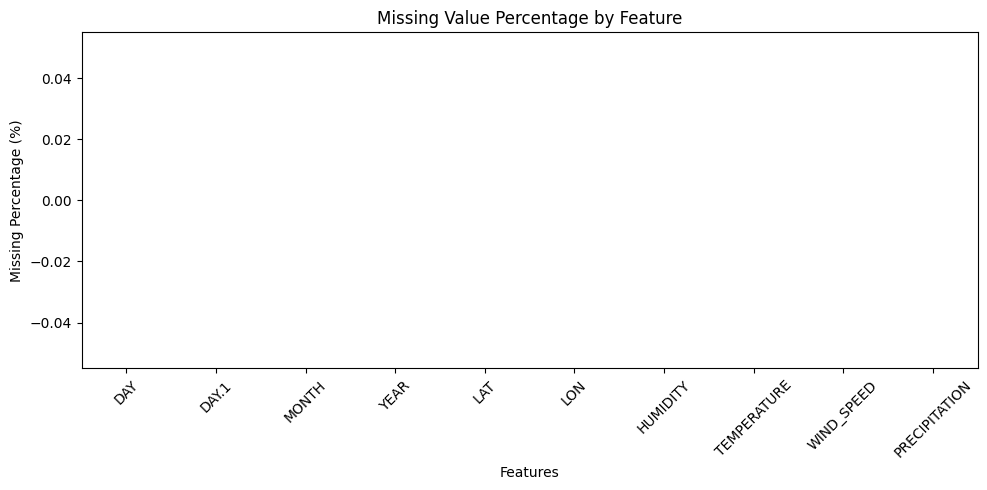

Total Duplicate Records: 0


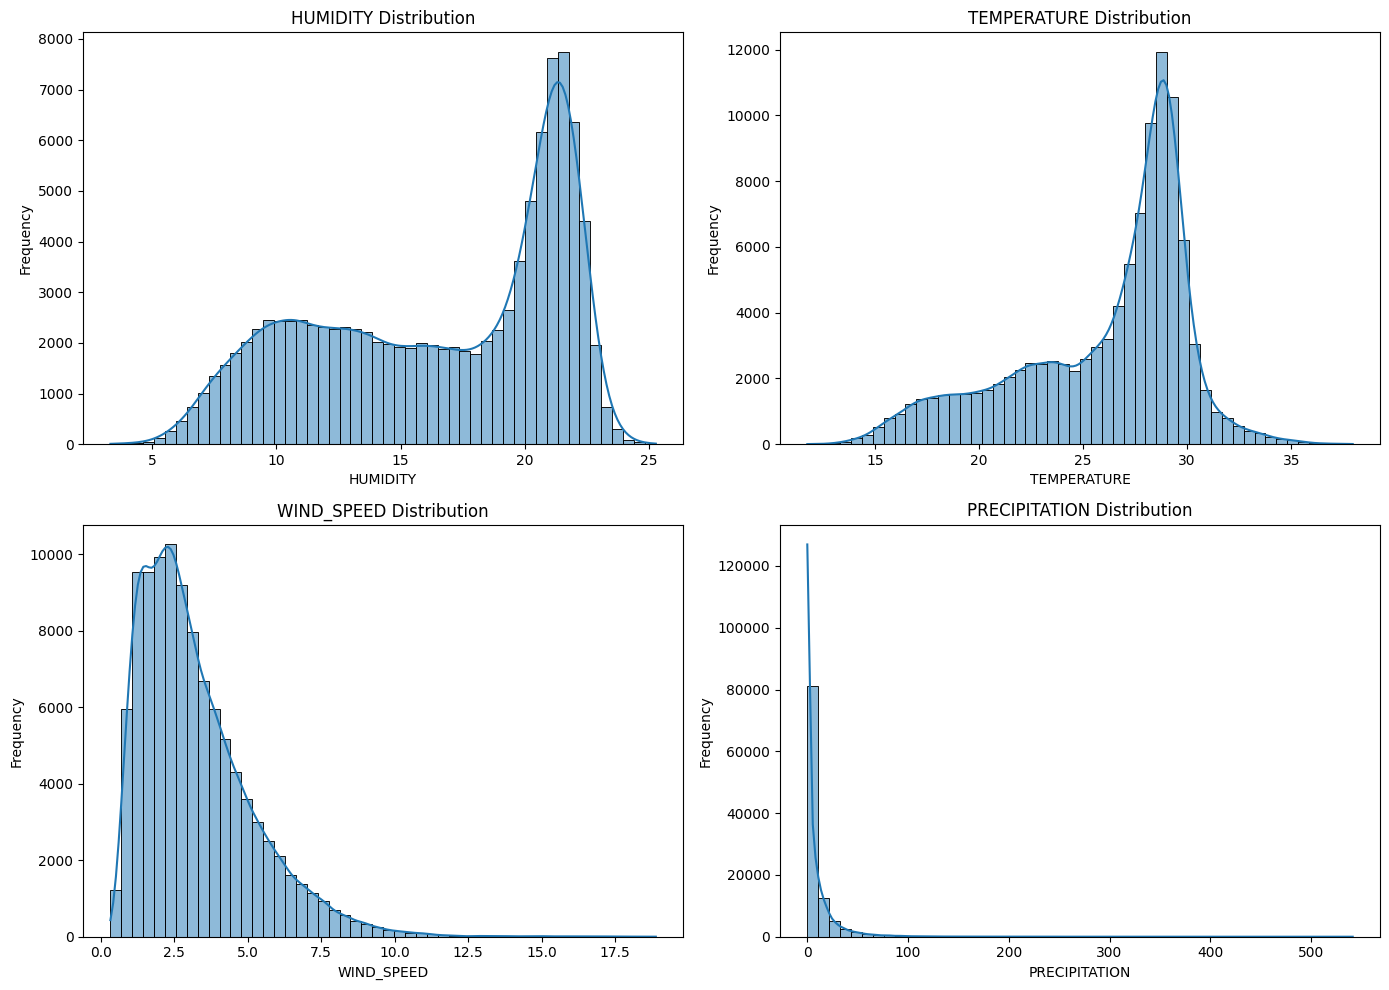

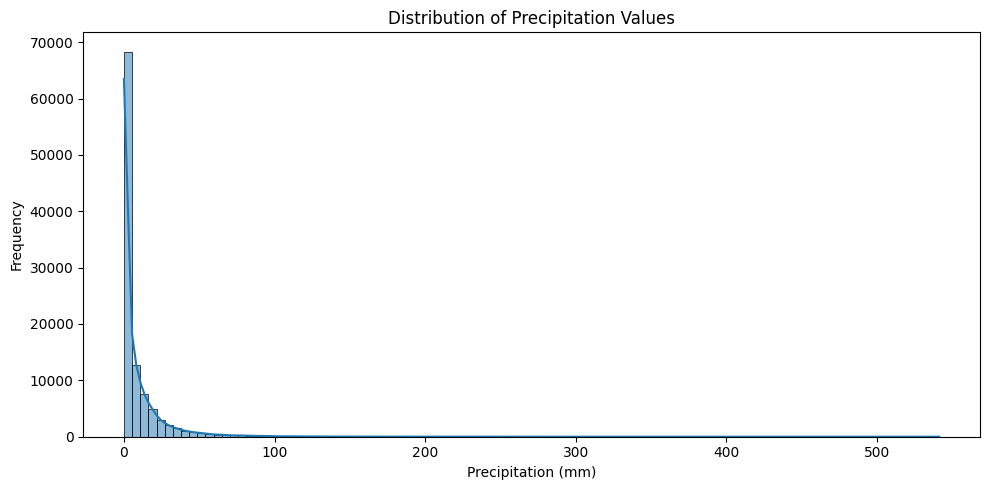


Precipitation Statistics


count    105192.000000
mean          8.655601
std          19.476785
min           0.000000
25%           0.000000
50%           1.440000
75%           9.700000
max         541.410000
Name: PRECIPITATION, dtype: float64

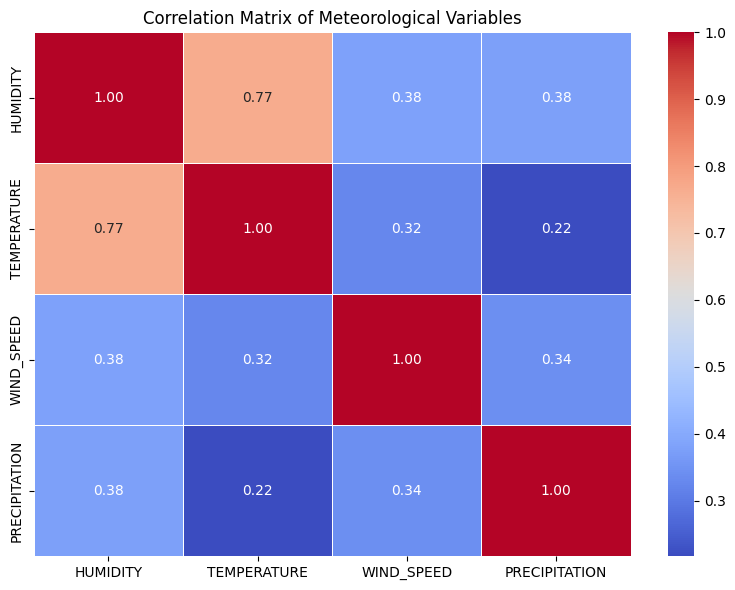


Final Dataset Overview
--------------------------------
Rows: 105192
Columns: 10
Missing Values: 0
Duplicate Rows: 0


In [72]:


import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Reproducibility
SEED = 42
np.random.seed(SEED)

print("Libraries imported successfully")

DATA_PATH = "/kaggle/input/datasets/mdforhadmia/daily-weather-data/daily_weather_data.csv"

# Load dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully")
print("--------------------------------")
print("Dataset Shape:", df.shape)

# ============================================================
# 3. Dataset Structure Inspection
# ============================================================

print("\nDataset Information")
print("--------------------------------")

df.info()

# Display first five records

print("\nFirst Five Records")
print("--------------------------------")

display(df.head())

# ============================================================
# 4. Feature Identification
# ============================================================
print("\nDataset Features")
print("--------------------------------")

for index, column in enumerate(df.columns, start=1):
    print(index, ".", column)

# Separate feature categories
temporal_features = [
    "DAY",
    "MONTH",
    "YEAR"
]

spatial_features = [
    "LAT",
    "LON"
]

meteorological_features = [
    "HUMIDITY",
    "TEMPERATURE",
    "WIND_SPEED",
    "PRECIPITATION"
]

print("\nTemporal Features:")
print(temporal_features)
print("\nSpatial Features:")
print(spatial_features)
print("\nMeteorological Features:")
print(meteorological_features)

# ============================================================
# 5. Statistical Summary Analysis
# ============================================================

print("\nStatistical Summary")
print("--------------------------------")
display(
    df.describe().T
)

# Save summary table

stat_summary = df.describe().T

stat_summary.to_csv(
    "dataset_summary_statistics.csv"
)

# ============================================================
# 6. Missing Value Analysis
# ============================================================

print("\nMissing Value Analysis")
print("--------------------------------")


missing_analysis = pd.DataFrame({

    "Feature": df.columns,

    "Missing Count": df.isnull().sum(),

    "Missing Percentage":
    (df.isnull().sum()/len(df))*100

})

display(missing_analysis)

# Visualization

plt.figure(figsize=(10,5))

sns.barplot(
    data=missing_analysis,
    x="Feature",
    y="Missing Percentage"
)

plt.xticks(rotation=45)

plt.title(
    "Missing Value Percentage by Feature"
)

plt.ylabel(
    "Missing Percentage (%)"
)

plt.xlabel(
    "Features"
)


plt.tight_layout()

plt.show()



# ============================================================
# 7. Duplicate Record Checking
# ============================================================


duplicate_count = df.duplicated().sum()


print(
    "Total Duplicate Records:",
    duplicate_count
)

# ============================================================
# 8. Meteorological Variable Distribution
# ============================================================

weather_features = [

    "HUMIDITY",

    "TEMPERATURE",

    "WIND_SPEED",

    "PRECIPITATION"

]

plt.figure(
    figsize=(14,10)
)

for i, feature in enumerate(weather_features):

    plt.subplot(
        2,
        2,
        i+1
    )

    sns.histplot(
        df[feature],
        bins=50,
        kde=True
    )


    plt.title(
        f"{feature} Distribution"
    )

    plt.xlabel(feature)

    plt.ylabel("Frequency")

plt.tight_layout()

plt.show()
# ============================================================
# 9. Precipitation Distribution Analysis
# ============================================================

plt.figure(
    figsize=(10,5)
)
sns.histplot(
    df["PRECIPITATION"],
    bins=100,
    kde=True
)

plt.title(
    "Distribution of Precipitation Values"
)

plt.xlabel(
    "Precipitation (mm)"
)

plt.ylabel(
    "Frequency"
)

plt.tight_layout()

plt.show()

# Rainfall descriptive statistics

print("\nPrecipitation Statistics")

display(
    df["PRECIPITATION"].describe()
)


# 10. Correlation Analysis


correlation_features = [

    "HUMIDITY",

    "TEMPERATURE",

    "WIND_SPEED",

    "PRECIPITATION"

]

correlation_matrix = (
    df[correlation_features]
    .corr()
)


plt.figure(
    figsize=(8,6)
)

sns.heatmap(

    correlation_matrix,

    annot=True,

    fmt=".2f",

    cmap="coolwarm",

    linewidths=0.5
)

plt.title(
    "Correlation Matrix of Meteorological Variables"
)

plt.tight_layout()

plt.show()

# Save correlation matrix

correlation_matrix.to_csv(
    "correlation_matrix.csv"
)

# ============================================================
# 11. Dataset Final Check
# ============================================================

print("\nFinal Dataset Overview")
print("--------------------------------")

print(
    "Rows:",
    df.shape[0]
)

print(
    "Columns:",
    df.shape[1]
)

print(
    "Missing Values:",
    df.isnull().sum().sum()
)

print(
    "Duplicate Rows:",
    df.duplicated().sum()
)


# Step 02: Data Preprocessing and Feature Engineering


This step prepares the raw meteorological dataset for deep learning-based time-series forecasting. Since weather forecasting models require clean, structured, and temporally ordered input data, several preprocessing and feature engineering operations are applied.

The main objectives of this step are to improve data quality, extract meaningful temporal patterns, and create additional weather indicators that help deep learning models capture short-term and long-term atmospheric dependencies.

The following operations are performed:

1. Date feature construction and chronological ordering
2. Duplicate record removal
3. Missing value handling
4. Outlier inspection
5. Temporal feature engineering
6. Rainfall lag feature generation
7. Rolling precipitation feature generation
8. Seasonal encoding
9. Feature scaling
10. Final processed dataset preparation

The generated processed dataset will be used in the next step for sequence generation and deep learning model development.

In [1]:

# WeatherXAI-BD
# Step 02: Data Preprocessing and Feature Engineering


print("Initial Dataset Shape:")
print(df.shape)

display(df.head())
# ------------------------------------------------------------
# Create Date variable
# ------------------------------------------------------------

df["DATE"] = pd.to_datetime(
    df[["YEAR", "MONTH", "DAY"]]
)

# Sort by location and time
# Important for time-series forecasting

df = df.sort_values(
    by=[
        "LAT",
        "LON",
        "DATE"
    ]
).reset_index(drop=True)


print("Date creation and chronological sorting completed")

display(df.head())

# ------------------------------------------------------------
# Remove duplicate weather observations
# ------------------------------------------------------------
duplicate_before = df.shape[0]
df = df.drop_duplicates()
duplicate_after = df.shape[0]

print(
    "Removed duplicate records:",
    duplicate_before - duplicate_after
)
# ------------------------------------------------------------
# Missing value processing
# ------------------------------------------------------------

weather_columns = [

    "HUMIDITY",
    "TEMPERATURE",
    "WIND_SPEED",
    "PRECIPITATION"

]

print("Missing values before processing")

display(
    df[weather_columns].isnull().sum()
)

# Linear interpolation for continuous weather variables

df[weather_columns] = (
    df[weather_columns]
    .interpolate(
        method="linear"
    )
)

# Remaining missing values

df[weather_columns] = (
    df[weather_columns]
    .fillna(method="bfill")
    .fillna(method="ffill")
)

print("Missing values after processing")

display(
    df[weather_columns].isnull().sum()
)
# ------------------------------------------------------------
# Temporal feature creation
# ------------------------------------------------------------
# Day of year

df["DAY_OF_YEAR"] = (
    df["DATE"]
    .dt.dayofyear
)

# Cyclic month encoding

df["MONTH_SIN"] = np.sin(
    2 * np.pi * df["MONTH"] / 12
)

df["MONTH_COS"] = np.cos(
    2 * np.pi * df["MONTH"] / 12
)

print("Temporal features created")

display(
    df[
        [
            "DATE",
            "DAY_OF_YEAR",
            "MONTH_SIN",
            "MONTH_COS"
        ]
    ].head()
)
# ------------------------------------------------------------
# Historical rainfall dependency features
# ------------------------------------------------------------

lag_features = [1,7,14,30]


for lag in lag_features:

    df[f"PRECIP_LAG_{lag}"] = (

        df.groupby(
            [
                "LAT",
                "LON"
            ]
        )["PRECIPITATION"]
        .shift(lag)

    )

print("Rainfall lag features created")
display(
    df[
        [
            "PRECIPITATION",
            "PRECIP_LAG_1",
            "PRECIP_LAG_7",
            "PRECIP_LAG_14",
            "PRECIP_LAG_30"
        ]
    ].head(35)
)

# ------------------------------------------------------------
# Accumulated rainfall pattern features
# ------------------------------------------------------------

rolling_features = [7,14,30]


for window in rolling_features:

    df[f"PRECIP_ROLLING_{window}"] = (

        df.groupby(
            [
                "LAT",
                "LON"
            ]
        )["PRECIPITATION"]
        .rolling(
            window=window
        )
        .mean()
        .reset_index(
            level=[0,1],
            drop=True
        )

    )


print("Rolling rainfall features created")
display(
    df[
        [
            "PRECIPITATION",
            "PRECIP_ROLLING_7",
            "PRECIP_ROLLING_14",
            "PRECIP_ROLLING_30"
        ]
    ].head(35)
)

# ------------------------------------------------------------
# Atmospheric change indicators
# ------------------------------------------------------------

df["TEMP_CHANGE"] = (
    df.groupby(
        [
            "LAT",
            "LON"
        ]
    )["TEMPERATURE"]
    .diff()

)

df["HUMIDITY_CHANGE"] = (
    df.groupby(
        [
            "LAT",
            "LON"
        ]
    )["HUMIDITY"]
    .diff()

)

df["RAIN_CHANGE"] = (
    df.groupby(
        [
            "LAT",
            "LON"
        ]
    )["PRECIPITATION"]
    .diff()

)
print("Weather change indicators created")


# ------------------------------------------------------------
# Fill missing values created by feature engineering
# ------------------------------------------------------------
df = df.fillna(0)
print(
    "Remaining Missing Values:",
    df.isnull().sum().sum()
)
# ------------------------------------------------------------
# Final modelling features
# ------------------------------------------------------------

selected_features = [

    # Spatial
    "LAT",
    "LON",

    # Temporal
    "DAY_OF_YEAR",
    "MONTH_SIN",
    "MONTH_COS",

    # Weather variables
    "HUMIDITY",
    "TEMPERATURE",
    "WIND_SPEED",
    "PRECIPITATION",

    # Rainfall memory
    "PRECIP_LAG_1",
    "PRECIP_LAG_7",
    "PRECIP_LAG_14",
    "PRECIP_LAG_30",

    # Rainfall accumulation
    "PRECIP_ROLLING_7",
    "PRECIP_ROLLING_14",
    "PRECIP_ROLLING_30",
    
    # Change features
    "TEMP_CHANGE",
    "HUMIDITY_CHANGE",
    "RAIN_CHANGE"
]
processed_df = df[
    selected_features + ["DATE"]
].copy()
print(
    "Final processed dataset shape:",
    processed_df.shape
)
display(
    processed_df.head()
)
# ------------------------------------------------------------
# Save intermediate dataset
# ------------------------------------------------------------
processed_df.to_csv(
    "weather_feature_engineered_dataset.csv",
    index=False
)

Initial Dataset Shape:


NameError: name 'df' is not defined

# STEP 03: Label Generation, Data Scaling, Sequence

This step transforms the feature-engineered meteorological dataset into a supervised learning format suitable for deep learning-based weather forecasting.

Since the proposed WeatherXAI-BD framework performs both continuous forecasting and event-based prediction, additional prediction labels are generated for rainfall occurrence and extreme rainfall events.

The following operations are performed:

1. Rainfall occurrence label generation
2. Extreme rainfall event label generation using percentile threshold
3. Chronological train-validation-test splitting
4. Feature normalization using training data only
5. Sliding window sequence generation
6. Preparation of multi-task forecasting targets

The final output consists of sequential input tensors and multiple prediction targets required for LSTM, Transformer, and Hybrid LSTM–Transformer models.

1. Check Processed Dataset

In [74]:
# ============================================================
# WeatherXAI-BD
# Step 03: Label Generation and Sequence Preparation
# ============================================================

# processed_df is already available from Step 02

print("Processed Dataset Shape:")
print(processed_df.shape)

display(processed_df.head())

Processed Dataset Shape:
(105192, 20)


,LAT,LON,DAY_OF_YEAR,MONTH_SIN,MONTH_COS,HUMIDITY,TEMPERATURE,WIND_SPEED,PRECIPITATION,PRECIP_LAG_1,PRECIP_LAG_7,PRECIP_LAG_14,PRECIP_LAG_30,PRECIP_ROLLING_7,PRECIP_ROLLING_14,PRECIP_ROLLING_30,TEMP_CHANGE,HUMIDITY_CHANGE,RAIN_CHANGE,DATE
0,20.5,88.12,1,0.5,0.866025,10.47,23.80,4.41,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,2021-01-01
1,20.5,88.12,2,0.5,0.866025,10.42,23.49,4.15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.31,-0.05,0.0,2021-01-02
2,20.5,88.12,3,0.5,0.866025,10.28,23.51,2.88,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.02,-0.14,0.0,2021-01-03
3,20.5,88.12,4,0.5,0.866025,11.18,24.05,2.61,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.54,0.90,0.0,2021-01-04
4,20.5,88.12,5,0.5,0.866025,12.34,24.58,3.03,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.53,1.16,0.0,2021-01-05


2. Generate Rainfall Occurrence Label

In [75]:
# ------------------------------------------------------------
# Rainfall occurrence classification label
# ------------------------------------------------------------


processed_df["RAINFALL_OCCURRENCE"] = (
    processed_df["PRECIPITATION"]
    .apply(
        lambda x: 1 if x > 0 else 0
    )

)
print(
    "Rainfall occurrence distribution"
)

display(
    processed_df["RAINFALL_OCCURRENCE"]
    .value_counts()
)

Rainfall occurrence distribution


RAINFALL_OCCURRENCE
1    71297
0    33895
Name: count, dtype: int64

3. Generate Extreme Rainfall Label

In [76]:
# ------------------------------------------------------------
# Extreme rainfall event identification
# ------------------------------------------------------------


extreme_threshold = (
    processed_df["PRECIPITATION"]
    .quantile(0.95)

)

print(
    "Extreme Rainfall Threshold (P95):",
    extreme_threshold
)

processed_df["EXTREME_EVENT"] = (
    pocessed_df["PRECIPITATION"]
    .apply(
        lambda x: 1 if x >= extreme_threshold else 0
    )

)

print(
    "Extreme Event Distribution"
)

display(
    processed_df["EXTREME_EVENT"]
    .value_counts()
)

Extreme Rainfall Threshold (P95): 38.12449999999997
Extreme Event Distribution


EXTREME_EVENT
0    99932
1     5260
Name: count, dtype: int64

4. Check Target Balance
5. Select Final Model Features
6. Chronological Train Validation Test Split
7. Feature Scaling
8. Sliding Window Sequence Generation
9. Generate Train Validation Test Sequences
10. Save Prepared Data

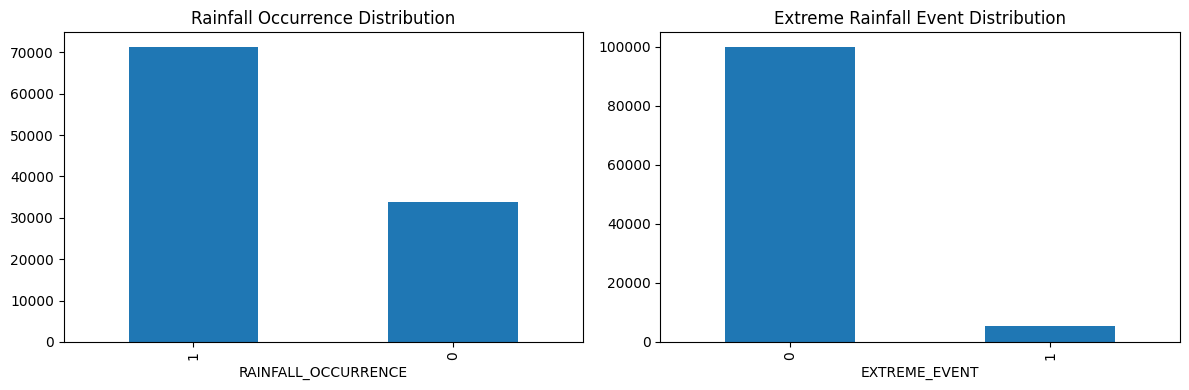

Input feature count: 19
Training: (73634, 22)
Validation: (15779, 22)
Testing: (15779, 22)
Feature scaling completed
Sequence Shapes
----------------
X_train: (73604, 30, 19)
Regression target: (73604, 4)
Occurrence target: (73604,)
Extreme target: (73604,)
Step 03 Completed Successfully


In [77]:
# ------------------------------------------------------------
# Visualization of target distribution
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12,4)
)

processed_df[
    "RAINFALL_OCCURRENCE"
].value_counts().plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title(
    "Rainfall Occurrence Distribution"
)

processed_df[
    "EXTREME_EVENT"
].value_counts().plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title(
    "Extreme Rainfall Event Distribution"
)


plt.tight_layout()
plt.show()
# ------------------------------------------------------------
# Input features and prediction targets
# ------------------------------------------------------------


input_features = [

    "LAT",
    "LON",

    "DAY_OF_YEAR",
    "MONTH_SIN",
    "MONTH_COS",

    "HUMIDITY",
    "TEMPERATURE",
    "WIND_SPEED",
    "PRECIPITATION",

    "PRECIP_LAG_1",
    "PRECIP_LAG_7",
    "PRECIP_LAG_14",
    "PRECIP_LAG_30",

    "PRECIP_ROLLING_7",
    "PRECIP_ROLLING_14",
    "PRECIP_ROLLING_30",

    "TEMP_CHANGE",
    "HUMIDITY_CHANGE",
    "RAIN_CHANGE"

]


target_features = [

    "TEMPERATURE",
    "HUMIDITY",
    "WIND_SPEED",
    "PRECIPITATION",
    "RAINFALL_OCCURRENCE",
    "EXTREME_EVENT"

]
print(
    "Input feature count:",
    len(input_features)
)
# ------------------------------------------------------------
# Chronological splitting
# ------------------------------------------------------------

dataset_length = len(processed_df)
train_end = int(
    dataset_length * 0.70
)

val_end = int(
    dataset_length * 0.85
)

train_df = processed_df.iloc[:train_end]
val_df = processed_df.iloc[
    train_end:val_end
]


test_df = processed_df.iloc[
    val_end:
]

print(
    "Training:",
    train_df.shape
)

print(
    "Validation:",
    val_df.shape
)

print(
    "Testing:",
    test_df.shape
)
# ------------------------------------------------------------
# Feature normalization
# ------------------------------------------------------------
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

# Fit only training data

train_df[input_features] = (
    scaler.fit_transform(
        train_df[input_features]
    )

)
val_df[input_features] = (
    scaler.transform(
        val_df[input_features]
    )
)
test_df[input_features] = (
    scaler.transform(
        test_df[input_features]
    )

)

print(
    "Feature scaling completed"
)
# ------------------------------------------------------------
# Sliding window function
# ------------------------------------------------------------

LOOK_BACK = 30

def create_sequences(data):

    X = []

    y_reg = []

    y_occ = []

    y_extreme = []

    feature_values = data[input_features].values

    temp_target = data[
        "TEMPERATURE"
    ].values

    humidity_target = data[
        "HUMIDITY"
    ].values

    wind_target = data[
        "WIND_SPEED"
    ].values

    precip_target = data[
        "PRECIPITATION"
    ].values

    occ_target = data[
        "RAINFALL_OCCURRENCE"
    ].values
    extreme_target = data[
        "EXTREME_EVENT"
    ].values

    for i in range(
        len(data)-LOOK_BACK
    ):

        X.append(
            feature_values[
                i:i+LOOK_BACK
            ]
        )

        y_reg.append(

            [
                temp_target[i+LOOK_BACK],
                humidity_target[i+LOOK_BACK],
                wind_target[i+LOOK_BACK],
                precip_target[i+LOOK_BACK]
            ]

        )

        y_occ.append(
            occ_target[i+LOOK_BACK]
        )


        y_extreme.append(
            extreme_target[i+LOOK_BACK]
        )
    return (

        np.array(X),

        np.array(y_reg),

        np.array(y_occ),

        np.array(y_extreme)

    )
    # ------------------------------------------------------------
# Generate sequences
# ------------------------------------------------------------

X_train, y_train_reg, y_train_occ, y_train_extreme = create_sequences(train_df)
X_val, y_val_reg, y_val_occ, y_val_extreme = create_sequences(val_df)
X_test, y_test_reg, y_test_occ, y_test_extreme = create_sequences(test_df)

print("Sequence Shapes")
print("----------------")
print(
    "X_train:",
    X_train.shape
)

print(
    "Regression target:",
    y_train_reg.shape
)

print(
    "Occurrence target:",
    y_train_occ.shape
)

print(
    "Extreme target:",
    y_train_extreme.shape
)
# ------------------------------------------------------------
# Save numpy arrays
# ------------------------------------------------------------

np.save(
    "X_train.npy",
    X_train
)

np.save(
    "X_val.npy",
    X_val
)

np.save(
    "X_test.npy",
    X_test
)

np.save(
    "y_train_reg.npy",
    y_train_reg
)
np.save(
    "y_test_reg.npy",
    y_test_reg
)

print(
    "Step 03 Completed Successfully"
)

# STEP 04: Deep Learning Model Development and Training


This step develops the proposed deep learning forecasting models using the prepared sequential meteorological dataset. Three architectures, including LSTM, Transformer, and Hybrid LSTM–Transformer, are implemented to evaluate their capability for multi-task weather forecasting.

The models receive historical weather sequences and simultaneously predict continuous meteorological variables, rainfall occurrence, and extreme rainfall events.

The following tasks are performed:

1. Deep learning environment setup
2. Multi-output forecasting architecture design
3. LSTM model development
4. Transformer model development
5. Hybrid LSTM–Transformer model development
6. Model compilation
7. Model training using validation monitoring
8. Saving trained models and training history

In [78]:
# ============================================================
# WeatherXAI-BD
# Step 04: Deep Learning Model Development and Training
# ============================================================


import tensorflow as tf

from tensorflow.keras.models import Model

from tensorflow.keras.layers import (
    Input,
    Dense,
    LSTM,
    Dropout,
    LayerNormalization,
    MultiHeadAttention,
    GlobalAveragePooling1D,
    Add
)

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)


import matplotlib.pyplot as plt

import numpy as np


print("TensorFlow Version:")
print(tf.__version__)
X_train
X_val
X_test


TensorFlow Version:
2.19.0


array([[[1.16666667, 0.71461187, 0.8       , ..., 0.63763441,
         0.44599303, 0.47877314],
        [1.16666667, 0.71461187, 0.80273973, ..., 0.52150538,
         0.35400697, 0.45235749],
        [1.16666667, 0.71461187, 0.80547945, ..., 0.35698925,
         0.18188153, 0.47542925],
        ...,
        [1.16666667, 0.71461187, 0.8739726 , ..., 0.53978495,
         0.41533101, 0.47191765],
        [1.16666667, 0.71461187, 0.87671233, ..., 0.50107527,
         0.31498258, 0.47174993],
        [1.16666667, 0.71461187, 0.87945205, ..., 0.6       ,
         0.29965157, 0.47437053]],

       [[1.16666667, 0.71461187, 0.80273973, ..., 0.52150538,
         0.35400697, 0.45235749],
        [1.16666667, 0.71461187, 0.80547945, ..., 0.35698925,
         0.18188153, 0.47542925],
        [1.16666667, 0.71461187, 0.80821918, ..., 0.6344086 ,
         0.45087108, 0.47133064],
        ...,
        [1.16666667, 0.71461187, 0.87671233, ..., 0.50107527,
         0.31498258, 0.47174993],
        [1.1

In [79]:
print("Training Input Shape:")
print(X_train.shape)

print("\nRegression Target Shape:")
print(y_train_reg.shape)

print("\nRainfall Occurrence Shape:")
print(y_train_occ.shape)
print("\nExtreme Event Shape:")
print(y_train_extreme.shape)

Training Input Shape:
(73604, 30, 19)

Regression Target Shape:
(73604, 4)

Rainfall Occurrence Shape:
(73604,)

Extreme Event Shape:
(73604,)


3. Define Multi-task Output Function

In [80]:
def compile_model(model):

    model.compile(

        optimizer=Adam(
            learning_rate=0.001
        ),
        loss={
            "regression_output":
            "mse",

            "occurrence_output":
            "binary_crossentropy",

            "extreme_output":
            "binary_crossentropy"
        },
        metrics={

            "regression_output":
            [
                "mae"
            ],

            "occurrence_output":
            [
                "accuracy"
            ],

            "extreme_output":
            [
                "accuracy"
            ]
        }

    )

    return model

# Build LSTM Model 

In [81]:
def build_lstm_model(input_shape):


    inputs = Input(
        shape=input_shape
    )
    x = LSTM(
        128,
        return_sequences=False
    )(inputs)
    x = Dropout(
        0.3
    )(x)
    # Regression output
    regression = Dense(
        4,
        activation="linear",
        name="regression_output"
    )(x)

    # Rainfall occurrence

    occurrence = Dense(
        1,
        activation="sigmoid",
        name="occurrence_output"
    )(x)
    # Extreme event
    extreme = Dense(
        1,
        activation="sigmoid",
        name="extreme_output"
    )(x)

    model = Model(
        inputs=inputs,
        outputs=[
            regression,
            occurrence,
            extreme
        ]

    )

    return compile_model(model)

lstm_model = build_lstm_model(
    X_train.shape[1:]
)

lstm_model.summary()


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_11      │ (None, 30, 19)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_6 (LSTM)       │ (None, 128)       │     75,776 │ input_layer_11[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_13          │ (None, 128)       │          0 │ lstm_6[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ regression_output   │ (None, 4)         │        516 │ dropout_13[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ occurrence_output   │ (None, 1)         │        129 │ dropout_13[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ extreme_output      │ (None, 1)         │        129 │ dropout_13[0][0]  │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 76,550 (299.02 KB)

 Trainable params: 76,550 (299.02 KB)

 Non-trainable params: 0 (0.00 B)

Transformer Model 

In [86]:
# ============================================================
# Transformer Model
# ============================================================

def transformer_block(
    inputs,
    head_size=64,
    num_heads=4,
    ff_dim=128
):

    # Multi-head self attention
    attention_output = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=head_size
    )(
        inputs,
        inputs
    )

    # Residual connection
    x = Add()(
        [
            inputs,
            attention_output
        ]
    )

    x = LayerNormalization()(x)



    # Feed Forward Network

    ff_output = Dense(
        ff_dim,
        activation="relu"
    )(x)

    # Match dimension

    ff_output = Dense(
        x.shape[-1]
    )(ff_output)

    # Second residual connection

    x = Add()(
        [
            x,
            ff_output
        ]
    )

    return LayerNormalization()(x)

# ============================================================
# Build Transformer Model
# ============================================================

def build_transformer_model(input_shape):

    inputs = Input(
        shape=input_shape
    )

    # Convert input features
    # 19 features -> 128 embedding dimension

    x = Dense(
        128
    )(inputs)

    # Transformer Encoder

    x = transformer_block(
        x
    )


    x = GlobalAveragePooling1D()(x)

    x = Dense(
        128,
        activation="relu"
    )(x)

    x = Dropout(
        0.3
    )(x)
    # Regression output

    regression = Dense(
        4,
        activation="linear",
        name="regression_output"
    )(x)

    # Rainfall occurrence output

    occurrence = Dense(
        1,
        activation="sigmoid",
        name="occurrence_output"
    )(x)

    # Extreme rainfall output

    extreme = Dense(
        1,
        activation="sigmoid",
        name="extreme_output"
    )(x)

    model = Model(
        inputs=inputs,
        outputs=[
            regression,
            occurrence,
            extreme
        ]
    )

    return compile_model(model)


In [87]:
transformer_model = build_transformer_model(
    X_train.shape[1:]
)


transformer_model.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_12      │ (None, 30, 19)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 30, 128)   │      2,560 │ input_layer_12[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 30, 128)   │    131,968 │ dense_7[0][0],    │
│ (MultiHeadAttentio… │                   │            │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_12 (Add)        │ (None, 30, 128)   │          0 │ dense_7[0][0],    │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 128)   │        256 │ add_12[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 30, 128)   │     16,512 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 30, 128)   │     16,512 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_13 (Add)        │ (None, 30, 128)   │          0 │ layer_normalizat… │
│                     │                   │            │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 128)   │        256 │ add_13[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 128)       │     16,512 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_15          │ (None, 128)       │          0 │ dense_10[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ regression_output   │ (None, 4)         │        516 │ dropout_15[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ occurrence_output   │ (None, 1)         │        129 │ dropout_15[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ extreme_output      │ (None, 1)         │        129 │ dropout_15[0][0]  │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 185,350 (724.02 KB)

 Trainable params: 185,350 (724.02 KB)

 Non-trainable params: 0 (0.00 B)

# MODEL 3: Hybrid LSTM–Transformer Model

In [88]:
def build_hybrid_model(input_shape):


    inputs = Input(
        shape=input_shape
    )

    x = LSTM(

        128,

        return_sequences=True

    )(inputs)



    x = Dropout(
        0.3
    )(x)



    x = transformer_block(
        x
    )



    x = GlobalAveragePooling1D()(x)



    x = Dense(

        128,

        activation="relu"

    )(x)



    x = Dropout(
        0.3
    )(x)



    regression = Dense(

        4,

        activation="linear",

        name="regression_output"

    )(x)

    occurrence = Dense(

        1,

        activation="sigmoid",

        name="occurrence_output"

    )(x)

    extreme = Dense(
        1,
        activation="sigmoid",

        name="extreme_output"

    )(x)

    model = Model(

        inputs,

        [

            regression,

            occurrence,

            extreme

        ]

    )
    return compile_model(model)

hybrid_model = build_hybrid_model(
    X_train.shape[1:]
)
hybrid_model.summary()

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_13      │ (None, 30, 19)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_7 (LSTM)       │ (None, 30, 128)   │     75,776 │ input_layer_13[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_16          │ (None, 30, 128)   │          0 │ lstm_7[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 30, 128)   │    131,968 │ dropout_16[0][0], │
│ (MultiHeadAttentio… │                   │            │ dropout_16[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_14 (Add)        │ (None, 30, 128)   │          0 │ dropout_16[0][0], │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 128)   │        256 │ add_14[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 30, 128)   │     16,512 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 30, 128)   │     16,512 │ dense_11[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_15 (Add)        │ (None, 30, 128)   │          0 │ layer_normalizat… │
│                     │                   │            │ dense_12[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 128)   │        256 │ add_15[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 128)       │     16,512 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_18          │ (None, 128)       │          0 │ dense_13[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ regression_output   │ (None, 4)         │        516 │ dropout_18[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ occurrence_output   │ (None, 1)         │        129 │ dropout_18[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ extreme_output      │ (None, 1)         │        129 │ dropout_18[0][0]  │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 258,566 (1010.02 KB)

 Trainable params: 258,566 (1010.02 KB)

 Non-trainable params: 0 (0.00 B)

In [90]:
early_stop = EarlyStopping(

    monitor="val_loss",
    patience=10,
    restore_best_weights=True

)
reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",
    factor=0.5,
    patience=5

)

In [91]:
history_lstm = lstm_model.fit(

    X_train,
    [
        y_train_reg,
        y_train_occ,
        y_train_extreme
    ],

    validation_data=(
        X_val,
        [
            y_val_reg,
            y_val_occ,
            y_val_extreme
        ]
    ),

    epochs=100,
    batch_size=64,
    callbacks=[
        early_stop,
        reduce_lr

    ]

)

Epoch 1/100
1151/1151 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - extreme_output_accuracy: 0.9409 - extreme_output_loss: 0.1981 - loss: 0.5916 - occurrence_output_accuracy: 0.8251 - occurrence_output_loss: 0.3605 - regression_output_loss: 0.0330 - regression_output_mae: 0.1310 - val_extreme_output_accuracy: 0.9758 - val_extreme_output_loss: 0.0966 - val_loss: 0.4243 - val_occurrence_output_accuracy: 0.8528 - val_occurrence_output_loss: 0.3232 - val_regression_output_loss: 0.0048 - val_regression_output_mae: 0.0486 - learning_rate: 0.0010
Epoch 2/100
1151/1151 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - extreme_output_accuracy: 0.9440 - extreme_output_loss: 0.1568 - loss: 0.4512 - occurrence_output_accuracy: 0.8673 - occurrence_output_loss: 0.2888 - regression_output_loss: 0.0056 - regression_output_mae: 0.0533 - val_extreme_output_accuracy: 0.9752 - val_extreme_output_loss: 0.0888 - val_loss: 0.3632 - val_occurrence_output_accuracy: 0.8807 - val_occurrence_output_loss: 0.2702 - val_regression_output_

**Train Transformer MOdel**

In [92]:
history_transformer = transformer_model.fit(

    X_train,
    [
        y_train_reg,
        y_train_occ,
        y_train_extreme
    ],

    validation_data=(
        X_val,

        [
            y_val_reg,
            y_val_occ,
            y_val_extreme
        ]
    ),


    epochs=100,
    batch_size=64,
    callbacks=[
        early_stop,
        reduce_lr

    ]

)

Epoch 1/100


I0000 00:00:1789478701.574584     269 service.cc:152] XLA service 0x7efc98519890 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1789478701.574648     269 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1789478701.574655     269 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5


  26/1151 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - extreme_output_accuracy: 0.8312 - extreme_output_loss: 0.3832 - loss: 1.4031 - occurrence_output_accuracy: 0.7080 - occurrence_output_loss: 0.5423 - regression_output_loss: 0.4776 - regression_output_mae: 0.5180

I0000 00:00:1789478705.894915     269 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1151/1151 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - extreme_output_accuracy: 0.9359 - extreme_output_loss: 0.2062 - loss: 0.6357 - occurrence_output_accuracy: 0.8270 - occurrence_output_loss: 0.3604 - regression_output_loss: 0.0691 - regression_output_mae: 0.1735 - val_extreme_output_accuracy: 0.9758 - val_extreme_output_loss: 0.1166 - val_loss: 0.4678 - val_occurrence_output_accuracy: 0.8424 - val_occurrence_output_loss: 0.3433 - val_regression_output_loss: 0.0066 - val_regression_output_mae: 0.0593 - learning_rate: 0.0010
Epoch 2/100
1151/1151 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - extreme_output_accuracy: 0.9417 - extreme_output_loss: 0.1777 - loss: 0.5079 - occurrence_output_accuracy: 0.8492 - occurrence_output_loss: 0.3211 - regression_output_loss: 0.0091 - regression_output_mae: 0.0689 - val_extreme_output_accuracy: 0.9758 - val_extreme_output_loss: 0.1120 - val_loss: 0.4663 - val_occurrence_output_accuracy: 0.8347 - val_occurrence_output_loss: 0.3473 - val_regression_output_loss: 0.0056 

**Train hybrid Model**

In [93]:
history_hybrid = hybrid_model.fit(

    X_train,
    [
        y_train_reg,
        y_train_occ,
        y_train_extreme
    ],

    validation_data=(
        X_val,
        [
            y_val_reg,
            y_val_occ,
            y_val_extreme
        ]
    ),


    epochs=100,
    batch_size=64,
    callbacks=[
        early_stop,
        reduce_lr
    ]

)

Epoch 1/100
1151/1151 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - extreme_output_accuracy: 0.9404 - extreme_output_loss: 0.1996 - loss: 0.6295 - occurrence_output_accuracy: 0.8209 - occurrence_output_loss: 0.3718 - regression_output_loss: 0.0580 - regression_output_mae: 0.1630 - val_extreme_output_accuracy: 0.9758 - val_extreme_output_loss: 0.1064 - val_loss: 0.4584 - val_occurrence_output_accuracy: 0.8441 - val_occurrence_output_loss: 0.3430 - val_regression_output_loss: 0.0078 - val_regression_output_mae: 0.0644 - learning_rate: 0.0010
Epoch 2/100
1151/1151 ━━━━━━━━━━━━━━━━━━━━ 17s 14ms/step - extreme_output_accuracy: 0.9400 - extreme_output_loss: 0.1863 - loss: 0.5272 - occurrence_output_accuracy: 0.8400 - occurrence_output_loss: 0.3322 - regression_output_loss: 0.0087 - regression_output_mae: 0.0674 - val_extreme_output_accuracy: 0.9758 - val_extreme_output_loss: 0.1072 - val_loss: 0.4802 - val_occurrence_output_accuracy: 0.8141 - val_occurrence_output_loss: 0.3650 - val_regression_output

8. Save Models

In [94]:
lstm_model.save(
    "WeatherXAI_LSTM.keras"
)

transformer_model.save(
    "WeatherXAI_Transformer.keras"
)

hybrid_model.save(
    "WeatherXAI_Hybrid_LSTM_Transformer.keras"
)

print(
    "All models saved successfully"
)

All models saved successfully


# STEP 05: Model Evaluation, Explainability and Agricultural Risk Assessment
Section Summary

This step evaluates the performance of the developed deep learning models and interprets their prediction behavior using explainable artificial intelligence techniques.

The trained LSTM, Transformer, and Hybrid LSTM–Transformer models are evaluated using regression and classification performance metrics. Regression performance is assessed using MAE, MSE, RMSE, and R², while event-based predictions are evaluated using Accuracy, Precision, Recall, F1-score, and ROC-AUC.

Furthermore, Temporal SHAP analysis is applied to identify the contribution of historical weather variables and time steps toward model predictions. Finally, the predicted weather conditions are integrated into the Weather-Based Agricultural Risk Index (WARI) framework for agricultural risk assessment.

In [95]:
# ============================================================
# STEP 05
# Model Evaluation + SHAP + WARI
# ============================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import shap
print("Evaluation libraries loaded")


Evaluation libraries loaded


# 2. Generate Model Predictions
**LSTM Prediction**

In [96]:
# ------------------------------------------------------------
# Generate predictions
# ------------------------------------------------------------

lstm_predictions = lstm_model.predict(
    X_test
)

transformer_predictions = transformer_model.predict(
    X_test
)

hybrid_predictions = hybrid_model.predict(
    X_test
)

print("Prediction completed")

493/493 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
493/493 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
493/493 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Prediction completed


# 3. Extract Hybrid Model Output

(Primary proposed model)

In [97]:
# ============================================================
# Hybrid Model Outputs
# ============================================================

hybrid_reg_pred = hybrid_predictions[0]
hybrid_occ_pred = hybrid_predictions[1]
hybrid_extreme_pred = hybrid_predictions[2]

print(
    hybrid_reg_pred.shape
)

print(
    hybrid_occ_pred.shape
)

print(
    hybrid_extreme_pred.shape
)

(15749, 4)
(15749, 1)
(15749, 1)


**4. Regression Evaluation**
Target :
Temperature
Humidity
Wind Speed
Precipitation

In [98]:
# ============================================================
# Regression Performance
# ============================================================

regression_results = []
target_names = [

    "Temperature",
    "Humidity",
    "Wind Speed",
    "Precipitation"
]

for i,name in enumerate(target_names):
    mae = mean_absolute_error(
        y_test_reg[:,i],
        hybrid_reg_pred[:,i]
    )
    mse = mean_squared_error(
        y_test_reg[:,i],
        hybrid_reg_pred[:,i]
    )

    rmse = np.sqrt(mse)
    r2 = r2_score(
        y_test_reg[:,i],
        hybrid_reg_pred[:,i]
    )
    regression_results.append(
        [
            name,
            mae,
            mse,
            rmse,
            r2
        ]

    )

regression_results = pd.DataFrame(
    regression_results,
    columns=[

        "Variable",
        "MAE",
        "MSE",
        "RMSE",
        "R2"

    ]

)

display(
    regression_results
)
regression_results.to_csv(
    "hybrid_regression_results.csv",
    index=False
)

,Variable,MAE,MSE,RMSE,R2
0,Temperature,0.047491,0.003873,0.062234,0.880720
1,Humidity,0.059778,0.005970,0.077265,0.901530
2,Wind Speed,0.045424,0.003291,0.057369,0.219536
3,Precipitation,0.011123,0.000488,0.022081,0.267324


**Regression Prediction Graphs**

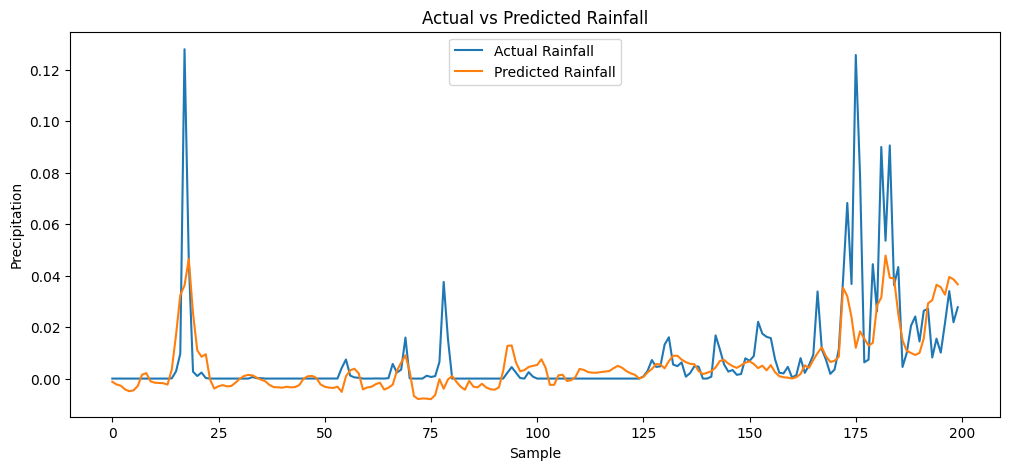

,Metric,Value
0,Accuracy,0.904502
1,Precision,0.922003
2,Recall,0.935234
3,F1-score,0.928571
4,ROC-AUC,0.963536


In [100]:
# ============================================================
# Rainfall Prediction Visualization
# ============================================================


plt.figure(figsize=(12,5))


plt.plot(

    y_test_reg[:200,3],

    label="Actual Rainfall"

)
plt.plot(

    hybrid_reg_pred[:200,3],
    label="Predicted Rainfall"
)

plt.title(
    "Actual vs Predicted Rainfall"
)
plt.xlabel(
    "Sample"
)

plt.ylabel(
    "Precipitation"
)
plt.legend()
plt.show()

# ============================================================
# Rainfall Occurrence Evaluation
# ============================================================

occ_pred_label = (
    hybrid_occ_pred > 0.5
).astype(int)

occ_accuracy = accuracy_score(
    y_test_occ,
    occ_pred_label
)
occ_precision = precision_score(
    y_test_occ,
    occ_pred_label
)
occ_recall = recall_score(
    y_test_occ,
    occ_pred_label
)


occ_f1 = f1_score(
    y_test_occ,
    occ_pred_label
)


occ_auc = roc_auc_score(
    y_test_occ,
    hybrid_occ_pred
)



occ_results = pd.DataFrame({
    "Metric":
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Value":
    [
        occ_accuracy,
        occ_precision,
        occ_recall,
        occ_f1,
        occ_auc
    ]
})
display(
    occ_results
)

# Extreme Rainfall Event Evaluation

In [101]:
# ============================================================
# Extreme Event Evaluation
# ============================================================
extreme_pred_label = (
    hybrid_extreme_pred > 0.5
).astype(int)

extreme_accuracy = accuracy_score(
    y_test_extreme,
    extreme_pred_label
)

extreme_precision = precision_score(
    y_test_extreme,
    extreme_pred_label
)
extreme_recall = recall_score(
    y_test_extreme,
    extreme_pred_label
)


extreme_f1 = f1_score(
    y_test_extreme,
    extreme_pred_label
)

extreme_auc = roc_auc_score(
    y_test_extreme,
    hybrid_extreme_pred
)



extreme_results = pd.DataFrame({
    "Metric":
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Value":
    [
        extreme_accuracy,
        extreme_precision,
        extreme_recall,
        extreme_f1,
        extreme_auc
    ]
})

display(
    extreme_results
)

,Metric,Value
0,Accuracy,0.965649
1,Precision,0.464912
2,Recall,0.099437
3,F1-score,0.163833
4,ROC-AUC,0.874339


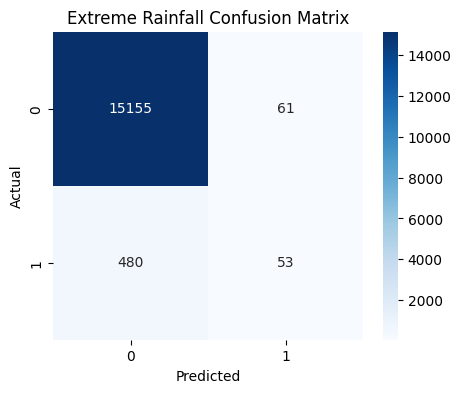

In [102]:
# ============================================================
# Extreme Event Confusion Matrix
# ============================================================

cm = confusion_matrix(
    y_test_extreme,
    extreme_pred_label
)

plt.figure(
    figsize=(5,4)
)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.title(
    "Extreme Rainfall Confusion Matrix"
)
plt.show()

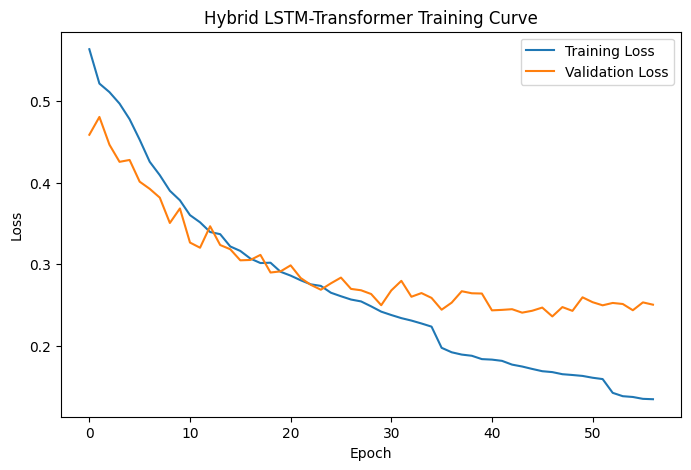

InvalidArgumentError: {{function_node __wrapped__Pack_N_3_device_/job:localhost/replica:0/task:0/device:GPU:0}} Shapes of all inputs must match: values[0].shape = [100,4] != values[1].shape = [100,1] [Op:Pack] name: packed

In [105]:
# ============================================================
# Training History
# ============================================================


plt.figure(figsize=(8,5))
plt.plot(
    history_hybrid.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_hybrid.history["val_loss"],
    label="Validation Loss"
)

plt.title(
    "Hybrid LSTM-Transformer Training Curve"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.legend()
plt.show()
# ============================================================
# Temporal SHAP Analysis
# ============================================================

background = X_train[:100]
sample_test = X_test[:50]

explainer = shap.DeepExplainer(
    hybrid_model,
    background

)

shap_values = explainer.shap_values(
    sample_test
)

print(
    "SHAP calculation completed"
)

# Temporal SHAP Explainability

In [108]:
# ============================================================
# Temporal SHAP Explainability
# Extreme Rainfall Prediction
# ============================================================

import shap
import tensorflow as tf
extreme_model = tf.keras.Model(
    inputs=hybrid_model.input,
    outputs=hybrid_model.output[2]
)
print(
    extreme_model.summary()
)

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_13      │ (None, 30, 19)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_7 (LSTM)       │ (None, 30, 128)   │     75,776 │ input_layer_13[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_16          │ (None, 30, 128)   │          0 │ lstm_7[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 30, 128)   │    131,968 │ dropout_16[0][0], │
│ (MultiHeadAttentio… │                   │            │ dropout_16[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_14 (Add)        │ (None, 30, 128)   │          0 │ dropout_16[0][0], │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 128)   │        256 │ add_14[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 30, 128)   │     16,512 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 30, 128)   │     16,512 │ dense_11[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_15 (Add)        │ (None, 30, 128)   │          0 │ layer_normalizat… │
│                     │                   │            │ dense_12[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 128)   │        256 │ add_15[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 128)       │     16,512 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_18          │ (None, 128)       │          0 │ dense_13[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ extreme_output      │ (None, 1)         │        129 │ dropout_18[0][0]  │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 257,921 (1007.50 KB)

 Trainable params: 257,921 (1007.50 KB)

 Non-trainable params: 0 (0.00 B)

None


In [109]:
# ------------------------------------------------------------
# SHAP background samples
# ------------------------------------------------------------

background = X_train[:100]
sample_test = X_test[:50]
print(
    "Background:",
    background.shape
)
print(
    "Test:",
    sample_test.shape
)

Background: (100, 30, 19)
Test: (50, 30, 19)


In [111]:
# ------------------------------------------------------------
# Gradient SHAP Explainer
# ------------------------------------------------------------
explainer = shap.GradientExplainer(
    extreme_model,
    background
)

print(
    "SHAP Explainer Created"
)
# ------------------------------------------------------------
# Calculate SHAP values
# ------------------------------------------------------------

shap_values = explainer.shap_values(
    sample_test
)
print(
    "SHAP calculation completed"
)
print(
    type(shap_values)
)


SHAP Explainer Created
SHAP calculation completed
<class 'numpy.ndarray'>


In [120]:
print(
    np.array(shap_values).shape
)
feature_importance = np.mean(
    np.abs(shap_array),
    axis=(0,1)
)
Dense(1, activation="sigmoid")

(50, 30, 19, 1)


<Dense name=dense_15, built=False>

In [121]:
# ============================================================
# Temporal SHAP Feature Importance (Fixed)
# ============================================================


shap_array = np.array(shap_values)
print("Original SHAP shape:")
print(shap_array.shape)

# Remove extra output dimension
shap_array = np.squeeze(
    shap_array
)

print("After squeeze:")
print(shap_array.shape)

# Average contribution:
# samples + time dimension
feature_importance = np.mean(
    np.abs(shap_array),
    axis=(0,1)
)
# Convert into 1D array
feature_importance = np.ravel(
    feature_importance
)
print(
    "Feature importance shape:",
    feature_importance.shape
)
# Create dataframe
shap_importance_df = pd.DataFrame({
    "Feature": input_features,
    "SHAP Importance": feature_importance
})



shap_importance_df = shap_importance_df.sort_values(
    by="SHAP Importance",
    ascending=False
)

display(
    shap_importance_df
)

Original SHAP shape:
(50, 30, 19, 1)
After squeeze:
(50, 30, 19)
Feature importance shape: (19,)


,Feature,SHAP Importance
4,MONTH_COS,7.301134e-04
2,DAY_OF_YEAR,7.227157e-04
3,MONTH_SIN,5.432166e-04
0,LAT,4.893278e-04
7,WIND_SPEED,3.760371e-04
1,LON,3.100961e-04
5,HUMIDITY,2.913562e-04
6,TEMPERATURE,2.196886e-04
17,HUMIDITY_CHANGE,8.114343e-05
12,PRECIP_LAG_30,7.418006e-05


In [123]:
shap_importance_df.to_csv(
    "temporal_shap_importance.csv",
    index=False
)

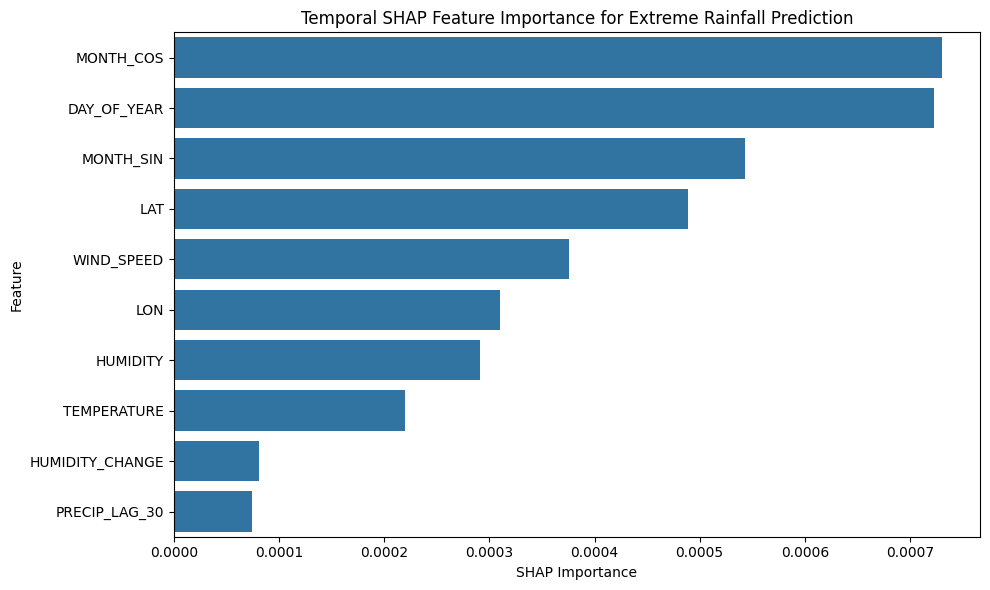

In [124]:
plt.figure(figsize=(10,6))
sns.barplot(
    data=shap_importance_df.head(10),
    x="SHAP Importance",
    y="Feature"
)
plt.title(
    "Temporal SHAP Feature Importance for Extreme Rainfall Prediction"
)
plt.tight_layout()
plt.show()

# STEP 05.11: Weather-Based Agricultural Risk Index (WARI)


This step converts the predicted weather conditions into an agricultural risk indicator. The proposed WeatherXAI-BD framework integrates rainfall intensity and extreme rainfall probability to estimate weather-related agricultural risk.

The Weather-Based Agricultural Risk Index (WARI) provides a simplified interpretation of forecasted weather conditions by categorizing future agricultural hazards into different risk levels.

The following operations are performed:

Extract predicted precipitation values
Calculate rainfall risk component
Integrate extreme rainfall probability
Compute WARI score
Generate agricultural risk categories
Visualize risk distribution

In [127]:
# ============================================================
# WARI Agricultural Risk Assessment
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print(
    "Regression Prediction Shape:",
    hybrid_reg_pred.shape
)
print(
    "Extreme Prediction Shape:",
    hybrid_extreme_pred.shape
)
# ------------------------------------------------------------
# Extract predicted weather variables
# ------------------------------------------------------------
wari_df = pd.DataFrame({
    "Predicted_Temperature":
    hybrid_reg_pred[:,0],
    
    "Predicted_Humidity":
    hybrid_reg_pred[:,1],

    "Predicted_Wind_Speed":
    hybrid_reg_pred[:,2],

    "Predicted_Rainfall":
    hybrid_reg_pred[:,3],

    "Extreme_Rainfall_Probability":
    hybrid_extreme_pred.flatten()
})

display(
    wari_df.head()
)

Regression Prediction Shape: (15749, 4)
Extreme Prediction Shape: (15749, 1)


,Predicted_Temperature,Predicted_Humidity,Predicted_Wind_Speed,Predicted_Rainfall,Extreme_Rainfall_Probability
0,0.353377,0.358580,0.122684,-0.001239,3.613291e-14
1,0.308604,0.336048,0.116839,-0.002296,2.213995e-14
2,0.298638,0.327250,0.115126,-0.002757,2.534327e-14
3,0.305562,0.327266,0.111215,-0.004192,2.487261e-12
4,0.286401,0.313779,0.101650,-0.004911,7.567974e-12


In [128]:
# ------------------------------------------------------------
# Rainfall risk normalization
# ------------------------------------------------------------

rainfall_risk = (

    wari_df["Predicted_Rainfall"]
    -
    wari_df["Predicted_Rainfall"].min()
) / (
    wari_df["Predicted_Rainfall"].max()
    -
    wari_df["Predicted_Rainfall"].min()
)

wari_df["Rainfall_Risk"] = rainfall_risk
display(
    wari_df.head()
)

,Predicted_Temperature,Predicted_Humidity,Predicted_Wind_Speed,Predicted_Rainfall,Extreme_Rainfall_Probability,Rainfall_Risk
0,0.353377,0.358580,0.122684,-0.001239,3.613291e-14,0.047215
1,0.308604,0.336048,0.116839,-0.002296,2.213995e-14,0.042595
2,0.298638,0.327250,0.115126,-0.002757,2.534327e-14,0.040580
3,0.305562,0.327266,0.111215,-0.004192,2.487261e-12,0.034308
4,0.286401,0.313779,0.101650,-0.004911,7.567974e-12,0.031163


In [129]:
# ------------------------------------------------------------
# Extreme rainfall risk
# ------------------------------------------------------------
wari_df["Extreme_Risk"] = (
    wari_df[
        "Extreme_Rainfall_Probability"
    ]
)
display(
    wari_df[
        [
        "Rainfall_Risk",
        "Extreme_Risk"
        ]
    ].head()
)

,Rainfall_Risk,Extreme_Risk
0,0.047215,3.613291e-14
1,0.042595,2.213995e-14
2,0.040580,2.534327e-14
3,0.034308,2.487261e-12
4,0.031163,7.567974e-12


# Calculate WARI Score

Formula:

WARI=0.6(Rainfall Risk)+0.4(Extreme Risk)

In [130]:
# ------------------------------------------------------------
# Weather Based Agricultural Risk Index
# ------------------------------------------------------------

wari_df["WARI"] = (
    0.6 *
    wari_df["Rainfall_Risk"]
    +
    0.4 *
    wari_df["Extreme_Risk"]
)

display(
    wari_df.head()
)

,Predicted_Temperature,Predicted_Humidity,Predicted_Wind_Speed,Predicted_Rainfall,Extreme_Rainfall_Probability,Rainfall_Risk,Extreme_Risk,WARI
0,0.353377,0.358580,0.122684,-0.001239,3.613291e-14,0.047215,3.613291e-14,0.028329
1,0.308604,0.336048,0.116839,-0.002296,2.213995e-14,0.042595,2.213995e-14,0.025557
2,0.298638,0.327250,0.115126,-0.002757,2.534327e-14,0.040580,2.534327e-14,0.024348
3,0.305562,0.327266,0.111215,-0.004192,2.487261e-12,0.034308,2.487261e-12,0.020585
4,0.286401,0.313779,0.101650,-0.004911,7.567974e-12,0.031163,7.567974e-12,0.018698


# Risk Classification

Risk levels:

0 - 0.3     Low Risk
0.3 - 0.6   Moderate Risk
>0.6        High Risk

In [132]:
# ------------------------------------------------------------
# Risk category generation
# ------------------------------------------------------------

def classify_risk(value):
    if value < 0.3:
        return "Low Risk"
    elif value < 0.6:
        return "Moderate Risk"
    else:
        return "High Risk"
wari_df["Risk_Category"] = (
    wari_df["WARI"]
    .apply(classify_risk)
)

display(
    wari_df[
        [
        "WARI",
        "Risk_Category"
        ]
    ].head()
)

,WARI,Risk_Category
0,0.028329,Low Risk
1,0.025557,Low Risk
2,0.024348,Low Risk
3,0.020585,Low Risk
4,0.018698,Low Risk


7. # Risk Distribution Table

In [133]:
# ------------------------------------------------------------
# WARI Risk Distribution
# ------------------------------------------------------------

risk_distribution = (
    wari_df["Risk_Category"]
    .value_counts()
    .reset_index()
)

risk_distribution.columns = [
    "Risk Category",
    "Number of Samples"
]

risk_distribution["Percentage"] = (
    risk_distribution[
        "Number of Samples"
    ]
    /
    len(wari_df)
    *
    100
)

display(
    risk_distribution
)
risk_distribution.to_csv(
    "WARI_risk_distribution.csv",
    index=False
)

,Risk Category,Number of Samples,Percentage
0,Low Risk,15473,98.247508
1,Moderate Risk,232,1.473109
2,High Risk,44,0.279383


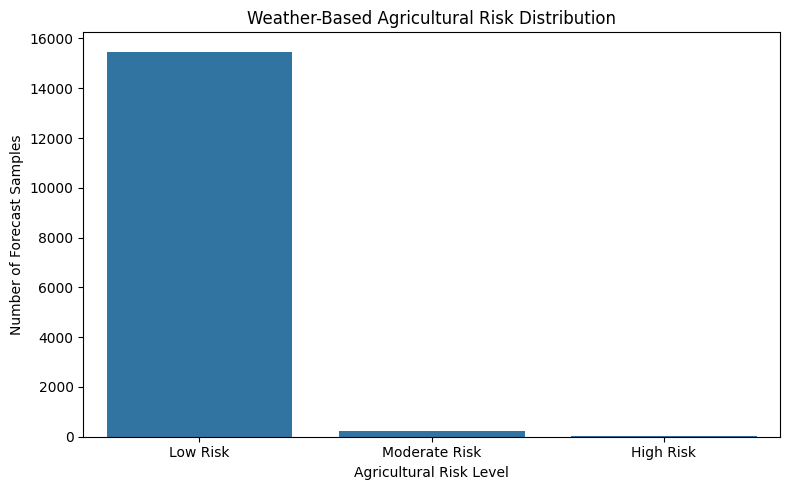

In [134]:
# ------------------------------------------------------------
# WARI Risk Distribution Plot
# ------------------------------------------------------------

plt.figure(
    figsize=(8,5)
)
sns.countplot(
    data=wari_df,
    x="Risk_Category"
)

plt.title(
    "Weather-Based Agricultural Risk Distribution"
)
plt.xlabel(
    "Agricultural Risk Level"
)
plt.ylabel(
    "Number of Forecast Samples"
)

plt.tight_layout()
plt.show()

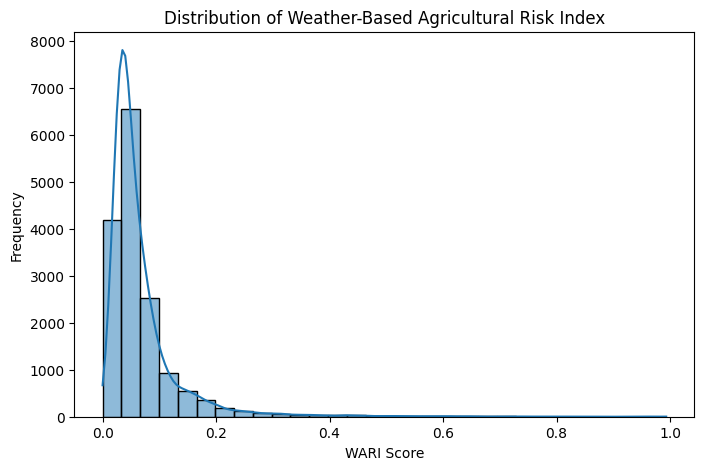

In [135]:
# ------------------------------------------------------------
# WARI score distribution
# ------------------------------------------------------------

plt.figure(
    figsize=(8,5)
)
sns.histplot(
    wari_df["WARI"],
    bins=30,
    kde=True
)

plt.title(
    "Distribution of Weather-Based Agricultural Risk Index"
)
plt.xlabel(
    "WARI Score"
)

plt.ylabel(
    "Frequency"
)
plt.show()

In [136]:
# ------------------------------------------------------------
# Save WARI prediction result
# ------------------------------------------------------------
wari_df.to_csv(
    "WARI_prediction_results.csv",
    index=False
)
print(
    "WARI Agricultural Risk Assessment Completed Successfully"
)

WARI Agricultural Risk Assessment Completed Successfully


# STEP 06: Automatic Result Generation for Thesis (Tables + Figures)
STEP 06: Thesis Result Table and Figure Generation
Section Summary (For Kaggle Notebook)

This step automatically generates quantitative evaluation tables and visualization outputs required for the results and discussion section. The generated results provide a comprehensive comparison of the proposed deep learning models and demonstrate forecasting performance, event detection capability, model learning behavior, explainability, and agricultural risk assessment outcomes.

The following outputs are generated:

Model performance comparison table
Regression evaluation table
Rainfall occurrence evaluation table
Extreme rainfall event evaluation table
Training performance curves
Prediction comparison plots
Model comparison visualization
SHAP importance visualization
WARI risk visualization

In [138]:
# ============================================================
# STEP 06
# Result Generation
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# ============================================================
# Regression Model Comparison
# ===========================================================
models = {
    "LSTM":
    lstm_predictions[0],

    "Transformer":
    transformer_predictions[0],

    "Hybrid LSTM-Transformer":
    hybrid_predictions[0]
}
regression_comparison = []
for model_name, prediction in models.items():
    rainfall_mae = mean_absolute_error(
        y_test_reg[:,3],
        prediction[:,3]
    )

    rainfall_rmse = np.sqrt(
        mean_squared_error(
            y_test_reg[:,3],
            prediction[:,3]
        )
    )
    rainfall_r2 = r2_score(
        y_test_reg[:,3],
        prediction[:,3]
    )
    regression_comparison.append(

        [
            model_name,
            rainfall_mae,
            rainfall_rmse,
            rainfall_r2
        ]

    )

regression_comparison_df = pd.DataFrame(
    regression_comparison,
    columns=[
        "Model",
        "MAE",
        "RMSE",
        "R2"
    ]
)
display(
    regression_comparison_df
)

regression_comparison_df.to_csv(
    "model_regression_comparison.csv",
    index=False
)
# ============================================================
# Extreme Event Model Comparison
# ============================================================
classification_models = []
"LSTM":
lstm_predictions[2]
"Transformer":
transformer_predictions[2],
"Hybrid LSTM-Transformer":
hybrid_predictions[2]
}
classification_results = []
for name,pred in classification_models.items():
    pred_label = (
        pred > 0.5
    ).astype(int)
    classification_results.append(
        [
            name,
            accuracy_score(
                y_test_extreme,
                pred_label
            ),

            precision_score(
                y_test_extreme,
                pred_label
            ),


            recall_score(
                y_test_extreme,
                pred_label
            ),

            f1_score(
                y_test_extreme,
                pred_label
            ),

            roc_auc_score(
                y_test_extreme,
                pred

            )

        ]

    )

classification_df = pd.DataFrame(
    classification_results,

    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"

    ]

)

display(
    classification_df
)


classification_df.to_csv(
    "extreme_event_model_comparison.csv",
    index=False

)

,Model,MAE,RMSE,R2
0,LSTM,0.011984,0.021957,0.275519
1,Transformer,0.020515,0.026664,-0.068417
2,Hybrid LSTM-Transformer,0.011123,0.022081,0.267324


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,LSTM,0.964823,0.440000,0.144465,0.217514,0.869560
1,Transformer,0.966982,0.600000,0.073171,0.130435,0.881509
2,Hybrid LSTM-Transformer,0.965649,0.464912,0.099437,0.163833,0.874339


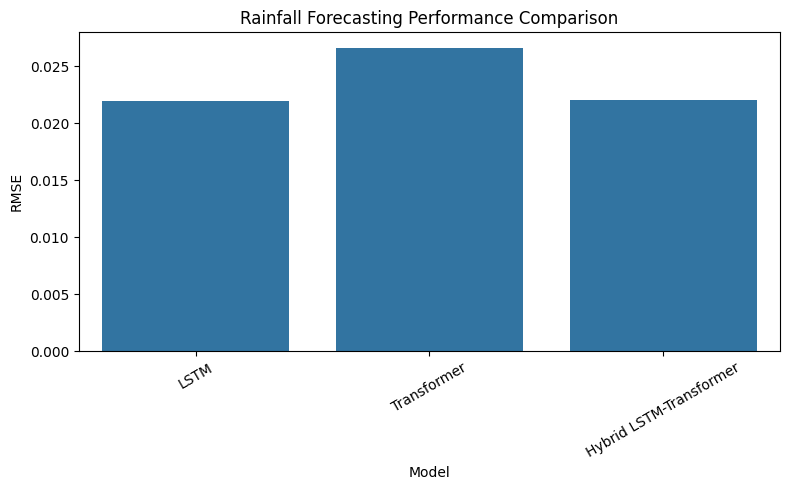

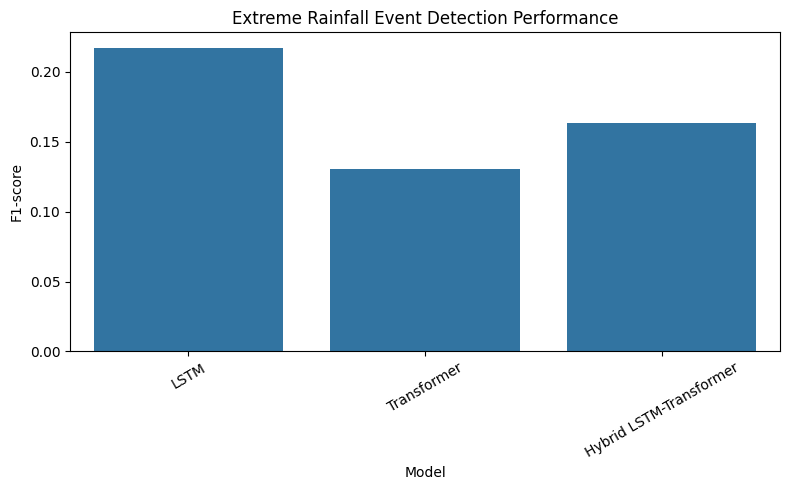

In [140]:
# ============================================================
# RMSE Comparison Plot
# ============================================================

plt.figure(figsize=(8,5))

sns.barplot(
    data=regression_comparison_df,
    x="Model",
    y="RMSE"
)
plt.xticks(
    rotation=30
)
plt.title(
    "Rainfall Forecasting Performance Comparison"
)
plt.tight_layout()
plt.show()
plt.figure(figsize=(8,5))

sns.barplot(
    data=classification_df,
    x="Model",
    y="F1-score"
)

plt.xticks(
    rotation=30
)

plt.title(
    "Extreme Rainfall Event Detection Performance"
)
plt.tight_layout()
plt.show()

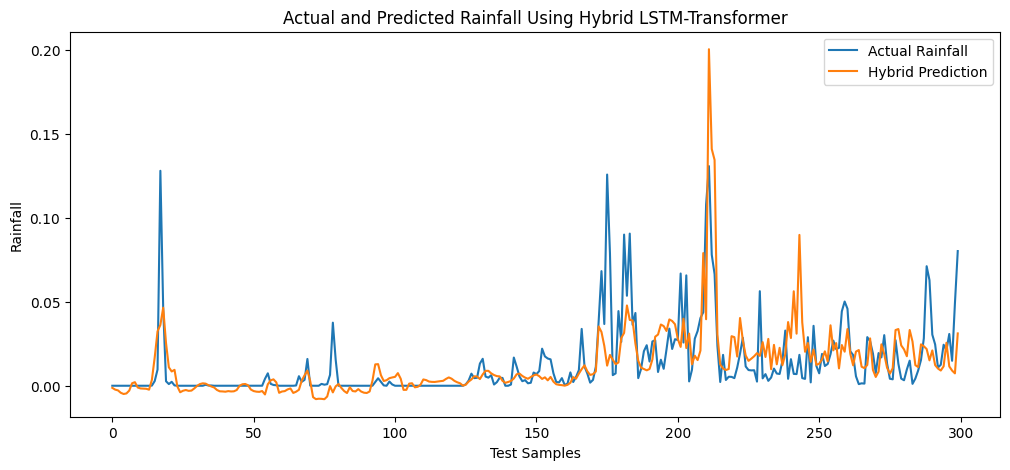

In [141]:
# ============================================================
# Hybrid Prediction Visualization
# ============================================================

plt.figure(figsize=(12,5))
plt.plot(
    y_test_reg[:300,3],
    label="Actual Rainfall"
)
plt.plot(
    hybrid_predictions[0][:300,3],
    label="Hybrid Prediction"
)

plt.title(
    "Actual and Predicted Rainfall Using Hybrid LSTM-Transformer"
)
plt.xlabel(
    "Test Samples"
)
plt.ylabel(
    "Rainfall"
)
plt.legend()
plt.show()

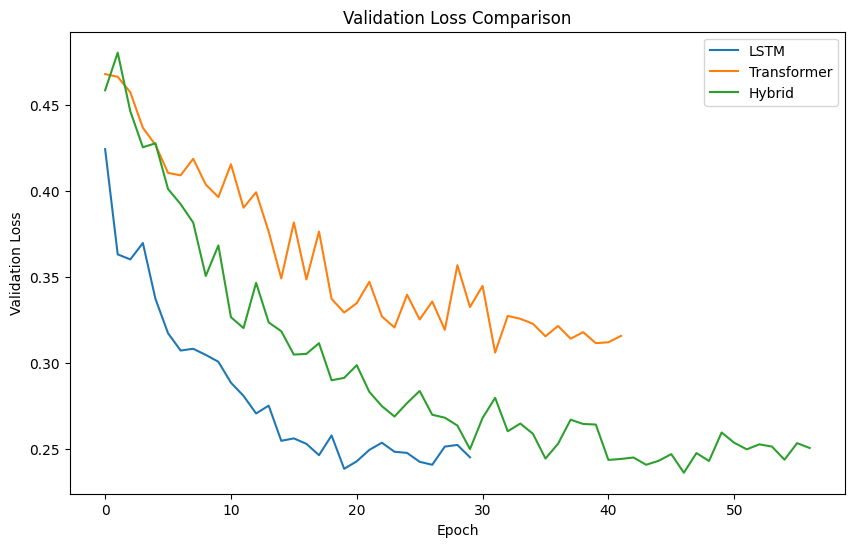

,Model,MAE,RMSE,R2,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,LSTM,0.011984,0.021957,0.275519,0.964823,0.440000,0.144465,0.217514,0.869560
1,Transformer,0.020515,0.026664,-0.068417,0.966982,0.600000,0.073171,0.130435,0.881509
2,Hybrid LSTM-Transformer,0.011123,0.022081,0.267324,0.965649,0.464912,0.099437,0.163833,0.874339


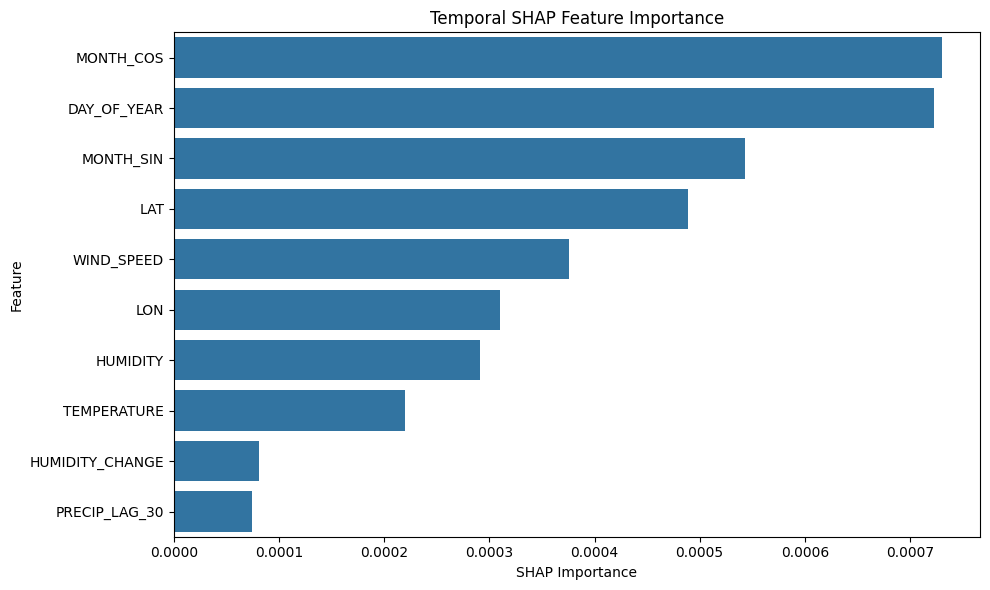

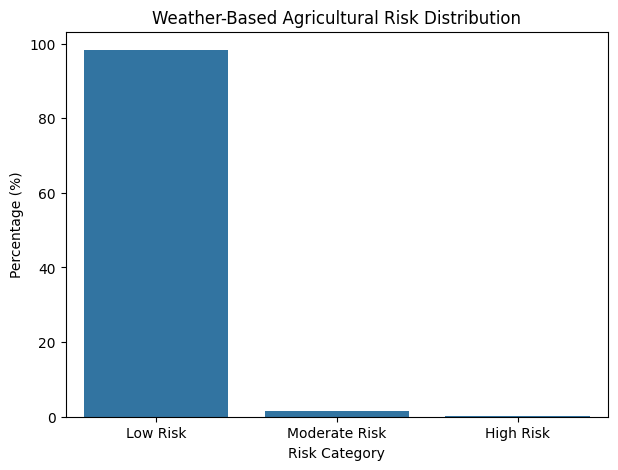

In [145]:
# ============================================================
# Training Loss Comparison
# ============================================================

plt.figure(figsize=(10,6))
plt.plot(
    history_lstm.history["val_loss"],
    label="LSTM"
)
plt.plot(
    history_transformer.history["val_loss"],
    label="Transformer"
)

plt.plot(
    history_hybrid.history["val_loss"],
    label="Hybrid"
)


plt.title(
    "Validation Loss Comparison"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Validation Loss"
)


plt.legend()
plt.show()
# ============================================================
# Final Performance Summary
# ============================================================

final_summary = pd.merge(
    regression_comparison_df,
    classification_df,
    on="Model"

)

display(
    final_summary
)

final_summary.to_csv(
    "final_model_performance_summary.csv",
    index=False
)
# ============================================================
# SHAP Figure
# ============================================================

plt.figure(figsize=(10,6))
sns.barplot(
    data=shap_importance_df.head(10),
    x="SHAP Importance",
    y="Feature"
)
plt.title(
    "Temporal SHAP Feature Importance"
)
plt.tight_layout()
plt.show()
# ============================================================
# WARI Figure
# ============================================================


plt.figure(figsize=(7,5))

sns.barplot(
    data=risk_distribution,
    x="Risk Category",
    y="Percentage"
)
plt.title(
    "Weather-Based Agricultural Risk Distribution"
)

plt.ylabel(
    "Percentage (%)"
)
plt.show()

# Final result output 

In [8]:
# ============================================================
# Export Results
# ============================================================


import os


os.makedirs(
    "final_results",
    exist_ok=True
)


os.makedirs(
    "final_figures",
    exist_ok=True
)


print(
    "Export folders created"
)


Export folders created


In [14]:
# Check available result variables

print(
    [x for x in dir() if "reg" in x.lower()]
)

[]
